# Úkol č. 1 - předzpracování dat a binární klasifikace

  * **Deadline je do 3. 11. 2022, 23:59:59**, pokud odevzdáte úkol do 10. 11. 2022, 23:59:59, budete penalizování -4 body, pozdější odevzdání je bez bodu.
  * V rámci tohoto úkolu se musíte vypořádat s příznaky, které jsou různých typů.
  * Před tím, než na nich postavíte predikční model, je třeba je nějakým způsobem převést do číselné reprezentace.
    
> **Úkoly jsou zadány tak, aby Vám daly prostor pro invenci. Vymyslet _jak přesně_ budete úkol řešit, je důležitou součástí zadání a originalita či nápaditost bude také hodnocena!**

## Zdroj dat

Budeme se zabývat predikcí přežití pasažérů Titaniku.
K dispozici máte trénovací data v souboru **data.csv** a data na vyhodnocení v souboru **evaluation.csv**.

#### Seznam příznaků:
* survived - zda přežil, 0 = Ne, 1 = Ano, **vysvětlovaná proměnná**, kterou chcete predikovat
* pclass - Třída lodního lístku, 1 = první, 2 = druhá, 3 = třetí
* name - jméno
* sex - pohlaví
* age - věk v letech
* sibsp	- počet sourozenců / manželů, manželek na palubě
* parch - počet rodičů / dětí na palubě
* ticket - číslo lodního lístku
* fare - cena lodního lístku
* cabin	- číslo kajuty
* embarked	- místo nalodění, C = Cherbourg, Q = Queenstown, S = Southampton
* home.dest - Bydliště/Cíl

## Pokyny k vypracování

**Základní body zadání**, za jejichž (poctivé) vypracování získáte **12 bodů**:
  * Využívejte buňky typu `Markdown` k vysvětlování Vašeho postupu. Za nepřehlednost budeme strhávat body.
  * V notebooku načtěte data ze souboru **data.csv**. Vhodným způsobem si je rozdělte na podmnožiny potřebné k trénování a evaluaci modelu (optimálně tedy trénovací, validační a testovací).
  * Projděte si jednotlivé příznaky a transformujte je do vhodné podoby pro použití ve vybraném klasifikačním modelu.
  * Podle potřeby si můžete vytvářet nové příznaky (na základě existujících), například tedy můžete vytvořit příznak měřící délku jména. Některé příznaky můžete také úplně zahodit. Pro průzkum dat využívejte vizualizace.
  * Nějakým způsobem se vypořádejte s chybějícími hodnotami.
  * Následně si vyberte vhodný klasifikační model z přednášek. Najděte vhodné hyperparametry a určete jeho přesnost (accuracy) na trénovací množině. Také určete jeho přesnost na testovací množině.
  * Načtěte vyhodnocovací data ze souboru **evaluation.csv**. Napočítejte predikce pro tyto data (vysvětlovaná proměnná v nich již není). Vytvořte **results.csv** soubor, ve kterém tyto predikce uložíte do dvou sloupců: ID, predikce přežití. Tento soubor též odevzdejte (uložte do projektu vedle notebooku).
  * Ukázka prvních řádků souboru *results.csv*:
  
```
ID,survived
1000,0
1001,1
...
```

**Další body zadání** za případné další body (můžete si vybrat, maximum bodů za úkol je každopádně 16 bodů):
  * (až +4 body) Aplikujte všechny klasifikační modely z přednášek a určete (na základě přesnosti na validační množině), který je nejlepší. Přesnost tohoto nejlepšího modelu odhadněte na testovací množině. K predikcím na vyhodnocovacích datech využijte tento model.
  * (až +4 body) Zaměřte se na optimální předzpracování dat. Zabývejte se tím, jak nejlépe zpracovat a reprezentovat kategoriální příznaky. Také zkuste data normalizovat. Zaměřte se na vliv těchto kroků na přesnost predikce výsledného modelu. K predikcím na vyhodnocovacích datech využijte ten přístup, který Vám vyjde jako nejlepší.

## Poznámky k odevzdání

  * Řiďte se pokyny ze stránky https://courses.fit.cvut.cz/BI-ML1/homeworks/index.html.
  * Vytvořte i csv soubor s predikcemi a uložte ho v rámci projektu (`results.csv`, vedle ipython notebooku).
  * Opravující Vám ve výjimečných případech může umožnit úkol dodělat či opravit a získat tak další body. První verze je ale stěžejní a má hlavní vliv na hodnocení.

<b>Start of project<b>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics, datasets
from sklearn.model_selection import train_test_split

Load data from <b> data.csv </b> into a dataframe and look at some basic metrics.


We can see that there are quite a few null values 
and that some attributes would better fit into some kind of category
intead of being represented as a string.

Also 1000 people should be enough to create a decent random sample. 

In [2]:
dataset = pd.read_csv("data.csv")
display(dataset.head())
display(dataset.shape)
display(dataset.isnull().sum())

,ID,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,home.dest
0,0,1,3,"Andersson, Mr. August Edvard (""Wennerstrom"")",male,27.0,0,0,350043,7.7958,NaN,S,NaN
1,1,1,3,"Dahl, Mr. Karl Edwart",male,45.0,0,0,7598,8.0500,NaN,S,"Australia Fingal, ND"
2,2,0,2,"Watson, Mr. Ennis Hastings",male,NaN,0,0,239856,0.0000,NaN,S,Belfast
3,3,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S,NaN
4,4,0,1,"Meyer, Mr. Edgar Joseph",male,28.0,1,0,PC 17604,82.1708,NaN,C,"New York, NY"


(1000, 13)

ID             0
survived       0
pclass         0
name           0
sex            0
age          203
sibsp          0
parch          0
ticket         0
fare           1
cabin        778
embarked       1
home.dest    427
dtype: int64

Let's check the ratio of people who survived to see whether there are significantly more 0's than 1's.

It seems to be a ~ 60:40 split so neither one is a rare one off occurence.

0    609
1    391
Name: survived, dtype: int64


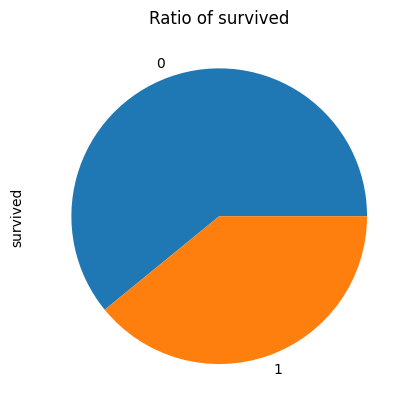

In [3]:
ax1 = dataset.survived.value_counts().plot(kind = 'pie')
ax1.set_title("Ratio of survived")
print(dataset["survived"].value_counts())

Looking at some other metrics we also see a relatively normal split.

male      646
female    354
Name: sex, dtype: int64


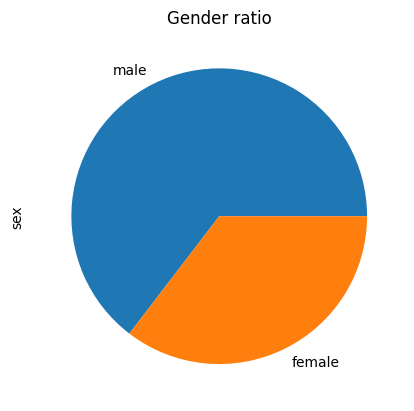

In [4]:
ax2 = dataset.sex.value_counts().plot(kind = 'pie')
ax2.set_title("Gender ratio")
print(dataset["sex"].value_counts())

In [5]:
print(dataset["sibsp"].value_counts())
print(dataset["parch"].value_counts())

0    677
1    246
2     34
4     18
3     15
8      6
5      4
Name: sibsp, dtype: int64
0    768
1    126
2     89
5      6
4      5
3      4
9      2
Name: parch, dtype: int64


In [6]:
display(dataset.describe())

,ID,survived,pclass,age,sibsp,parch,fare
count,1000.000000,1000.000000,1000.000000,797.000000,1000.000000,1000.000000,999.000000
mean,499.500000,0.391000,2.293000,30.006692,0.499000,0.384000,33.418514
std,288.819436,0.488219,0.840153,14.240416,1.020314,0.873675,53.115334
min,0.000000,0.000000,1.000000,0.166700,0.000000,0.000000,0.000000
25%,249.750000,0.000000,2.000000,21.000000,0.000000,0.000000,7.895800
50%,499.500000,0.000000,3.000000,28.000000,0.000000,0.000000,14.500000
75%,749.250000,1.000000,3.000000,38.500000,1.000000,0.000000,31.275000
max,999.000000,1.000000,3.000000,76.000000,8.000000,9.000000,512.329200


One interesting metric is <b>pclass</b>, which likely correlates with wealth or social status of a person.

We can see that a little over half of the people are in the lowest class while the other two get about 
a quarter each. 

3    542
1    249
2    209
Name: pclass, dtype: int64


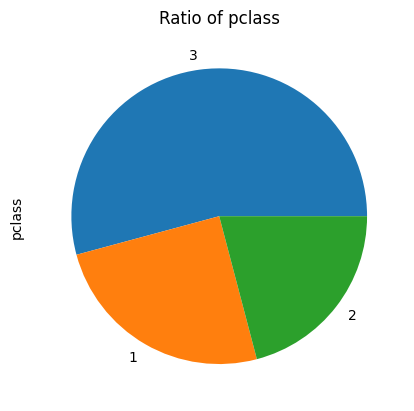

In [7]:
ax3 = dataset.pclass.value_counts().plot(kind = 'pie')
ax3.set_title("Ratio of pclass")
print(dataset["pclass"].value_counts())

<b>Age and pclass correlation</b>

The higher the pclass the older the avergare person and a higher chance of survival.

However this is not reflected in the mean survival age.
In fact, in every class older people survived less often,
thus the age disparity between pclasses does not seem to be a determining factor.



In [8]:
#rate of survived in each pclass
print("rate of survived in each pclass")
print(dataset[["pclass","survived"]].groupby(['pclass'], dropna=True).mean().round(4))
#mean age in each pclass
print("\nmean age in each pclass")
print(dataset[["pclass","age"]].groupby(['pclass'], dropna=True).mean().round(4))
#mean age of survived
print("\nmean age of survived")
print(dataset[["age","survived"]].groupby(['survived'], dropna=True).mean().round(4))

#mean age of survive in each pclass
print("\nmean age of survived in each pclass ")
datasettemp1 = dataset.loc[dataset['pclass'] == 1]
datasettemp2 = dataset.loc[dataset['pclass'] == 2]
datasettemp3 = dataset.loc[dataset['pclass'] == 3]
print(datasettemp1[["age","survived"]].groupby(['survived'], dropna=True).mean().round(4))
print(datasettemp2[["age","survived"]].groupby(['survived'], dropna=True).mean().round(4))
print(datasettemp3[["age","survived"]].groupby(['survived'], dropna=True).mean().round(4))

rate of survived in each pclass
        survived
pclass          
1         0.6225
2         0.4402
3         0.2657

mean age in each pclass
            age
pclass         
1       39.0134
2       29.3215
3       25.2561

mean age of survived
              age
survived         
0         30.4789
1         29.3244

mean age of survived in each pclass 
              age
survived         
0         42.8228
1         36.8327
              age
survived         
0         32.7963
1         25.1049
              age
survived         
0         26.1640
1         22.6515


<b> Family survival </b>

It seems that people with some relatives on board have a slightly higher chance of survival.

<i>It could be interesting, not present here, to create a family structure and see if size of the family matters or if some family members have a higher chance of survival than others.</i>

       survived
sibsp          
0        0.3530
1        0.5285
2        0.4118
3        0.4000
4        0.1111
5        0.0000
8        0.0000


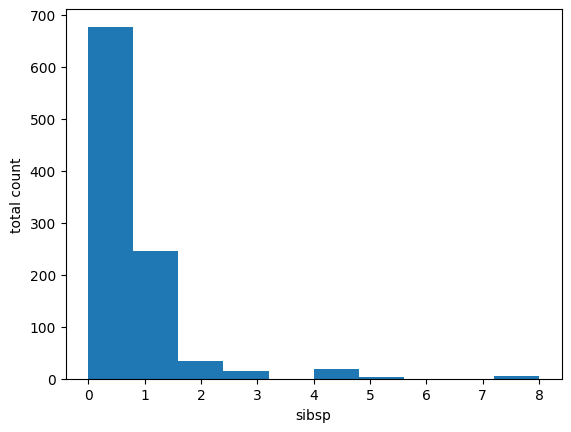

In [9]:
ax4 = dataset.sibsp.plot(kind = 'hist')
ax4.set_xlabel("sibsp")
ax4.set_ylabel("total count")
print(dataset[["sibsp","survived"]].groupby(['sibsp'], dropna=True).mean().round(4))

       survived
parch          
0        0.3438
1        0.6032
2        0.5056
3        1.0000
4        0.2000
5        0.1667
9        0.0000


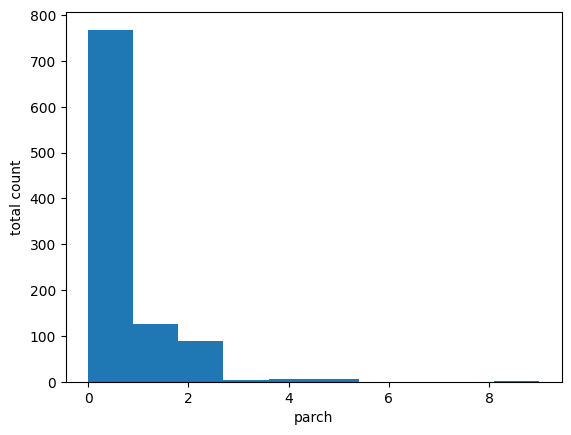

In [10]:
ax5 = dataset.parch.plot( kind = 'hist')
ax5.set_xlabel("parch")
ax5.set_ylabel("total count")
print(dataset[["parch","survived"]].groupby(['parch'], dropna=True).mean().round(4))

Some values seem to be more correlated, such as <i>sex </i> and <i>survived </i>. 
Others not very much so.

In [11]:
print(dataset[["sex","survived"]].groupby(['sex']).mean().round(4))
print(dataset[["sex","age"]].groupby(['sex']).mean().round(4))

        survived
sex             
female    0.7429
male      0.1981
            age
sex            
female  28.8259
male    30.6894


Let's check the general correlation matrix.
As we can see there are no very strong correlations, at least between the numerical attributes.

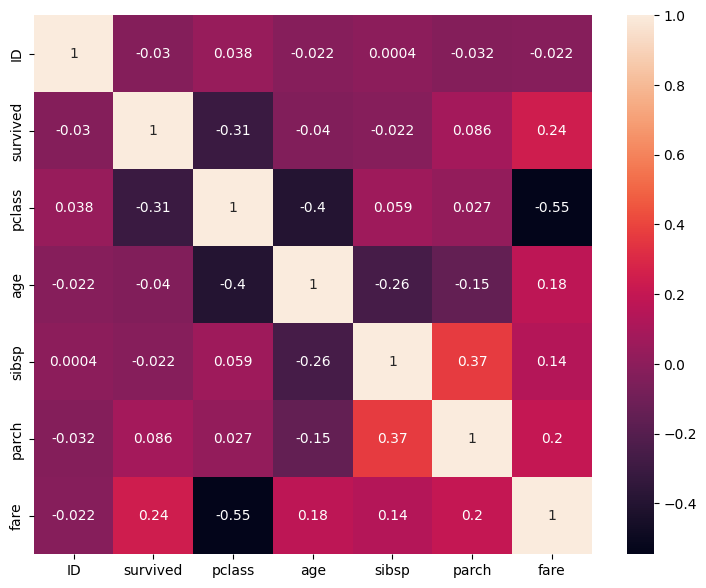

In [12]:
corr_matrix = dataset.corr()
plt.figure(figsize=(9,7))
sns.heatmap(corr_matrix, annot=True)
plt.show()

<b> Missing values </b>

In [13]:
dataset.isnull().sum()

ID             0
survived       0
pclass         0
name           0
sex            0
age          203
sibsp          0
parch          0
ticket         0
fare           1
cabin        778
embarked       1
home.dest    427
dtype: int64

In [14]:
#keep only rows where age is not null
#dataset = dataset[dataset['age'].notna()]

# assign mean age from pclasses
# dataset.loc[(dataset.pclass == 1) & (dataset.age.isnull() == True), 'age'] = dataset.loc[dataset['pclass'] == 1].age.mean().round(1)
# dataset.loc[(dataset.pclass == 2) & (dataset.age.isnull() == True), 'age'] = dataset.loc[dataset['pclass'] == 2].age.mean().round(1)
# dataset.loc[(dataset.pclass == 3) & (dataset.age.isnull() == True), 'age'] = dataset.loc[dataset['pclass'] == 3].age.mean().round(1)

dataset.loc[(dataset.pclass == 1) & (dataset.age.isnull() == True), 'age'] = -1
dataset.loc[(dataset.pclass == 2) & (dataset.age.isnull() == True), 'age'] = -1
dataset.loc[(dataset.pclass == 3) & (dataset.age.isnull() == True), 'age'] = -1

#check the modified age
#this ↓ only prints some of the rows
#display(dataset.age.head(100)) 

#this ↓ prints the whole dataset
#display(dataset.head(100))


dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         1000 non-null   int64  
 1   survived   1000 non-null   int64  
 2   pclass     1000 non-null   int64  
 3   name       1000 non-null   object 
 4   sex        1000 non-null   object 
 5   age        1000 non-null   float64
 6   sibsp      1000 non-null   int64  
 7   parch      1000 non-null   int64  
 8   ticket     1000 non-null   object 
 9   fare       999 non-null    float64
 10  cabin      222 non-null    object 
 11  embarked   999 non-null    object 
 12  home.dest  573 non-null    object 
dtypes: float64(2), int64(5), object(6)
memory usage: 101.7+ KB


Drop the single missing <b>fare</b> and <b>embarked</b> value.

In [15]:
dataset = dataset[dataset['fare'].notna()]
dataset = dataset[dataset['embarked'].notna()]

We will sort out missing values in <b>cabin</b> later.

Drop extra collumns, which are too complicated to sort nicely.
Perhaps after some deeper analysis, such as linking people with simillar ticket numbers we could see something but we won't even be linking family members together due to lack of time (not interest) on the authors side.
(something something.. progtest) 


In [16]:
ds = dataset.drop(["name", "home.dest","ID"], axis = 1)
ds.head()

,survived,pclass,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,3,male,27.0,0,0,350043,7.7958,NaN,S
1,1,3,male,45.0,0,0,7598,8.0500,NaN,S
2,0,2,male,-1.0,0,0,239856,0.0000,NaN,S
3,1,3,female,27.0,0,2,347742,11.1333,NaN,S
4,0,1,male,28.0,1,0,PC 17604,82.1708,NaN,C


<b> Change representation of objects </b>

First let's see what non numerical types we have: sex, cabin and embarked

In [17]:
display(ds.dtypes)
display(ds.nunique())

survived      int64
pclass        int64
sex          object
age         float64
sibsp         int64
parch         int64
ticket       object
fare        float64
cabin        object
embarked     object
dtype: object

survived      2
pclass        3
sex           2
age          94
sibsp         7
parch         7
ticket      752
fare        248
cabin       155
embarked      3
dtype: int64

In [18]:
display(ds.sex.unique())
display(ds.cabin.unique())
display(ds.embarked.unique())

array(['male', 'female'], dtype=object)

array([nan, 'C62 C64', 'D33', 'C23 C25 C27', 'B57 B59 B63 B66', 'C93',
       'E67', 'C97', 'B5', 'E45', 'A29', 'C148', 'B96 B98', 'C22 C26',
       'B94', 'E44', 'E63', 'E39 E41', 'D', 'B26', 'F G73', 'D15', 'C32',
       'C78', 'A34', 'F G63', 'A36', 'C111', 'C54', 'D7', 'B86', 'A14',
       'B52 B54 B56', 'T', 'E12', 'G6', 'C123', 'D19', 'B36', 'C125',
       'B51 B53 B55', 'E121', 'C106', 'C103', 'E8', 'F4', 'B49', 'B30',
       'E24', 'B58 B60', 'A18', 'B41', 'B71', 'C47', 'C118', 'C101',
       'E25', 'F E46', 'E17', 'C132', 'C68', 'B78', 'E101', 'E60', 'D22',
       'B4', 'A10', 'F E69', 'B69', 'E49', 'C52', 'C45', 'D49', 'C87',
       'C124', 'B82 B84', 'B79', 'C6', 'D6', 'E58', 'B42', 'C46', 'C85',
       'D36', 'A21', 'E36', 'F33', 'B24', 'D21', 'B45', 'E68', 'D56',
       'D35', 'B101', 'E46', 'D17', 'D50', 'C2', 'D28', 'F', 'D9', 'C86',
       'B3', 'B18', 'B73', 'D37', 'C82', 'C89', 'C31', 'E50', 'A26', 'F2',
       'D20', 'D26', 'B50', 'C65', 'D46', 'E31', 'C50', 'D38', '

array(['S', 'C', 'Q'], dtype=object)

Apply simple <b> one hot encoding</b> for <b> sex </b> and <b> embarked </b>

In [19]:
dummy_sex = pd.get_dummies(ds.sex)
dummy_embarked = pd.get_dummies(ds.embarked)

ds = pd.concat([ds, dummy_sex, dummy_embarked],axis='columns')
ds.drop(["sex", "embarked"], axis = 'columns',inplace=True)

ds.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 998 entries, 0 to 999
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  998 non-null    int64  
 1   pclass    998 non-null    int64  
 2   age       998 non-null    float64
 3   sibsp     998 non-null    int64  
 4   parch     998 non-null    int64  
 5   ticket    998 non-null    object 
 6   fare      998 non-null    float64
 7   cabin     221 non-null    object 
 8   female    998 non-null    uint8  
 9   male      998 non-null    uint8  
 10  C         998 non-null    uint8  
 11  Q         998 non-null    uint8  
 12  S         998 non-null    uint8  
dtypes: float64(2), int64(4), object(2), uint8(5)
memory usage: 75.0+ KB


Cabin letetrs on the Titanic were sorted from the top floor(A) all the way down(G). 
(with the exception of T which was on the very top). Thus location of ones cabin could correlate with where they were on a ship.
As a bonus this also simplifies the model.

<i>(A simillar pattern exists for the cabin numbers but is quite a bit more complicated.)</i>


In [20]:
ds["cabinstr"] = ds.cabin.astype(str)
ds['cabinletter'] = ds['cabinstr'].map(lambda name:name[0])
ds = ds.drop(["cabinstr"], axis = 1)

ds.head(10)

,survived,pclass,age,sibsp,parch,ticket,fare,cabin,female,male,C,Q,S,cabinletter
0,1,3,27.0,0,0,350043,7.7958,NaN,0,1,0,0,1,n
1,1,3,45.0,0,0,7598,8.0500,NaN,0,1,0,0,1,n
2,0,2,-1.0,0,0,239856,0.0000,NaN,0,1,0,0,1,n
3,1,3,27.0,0,2,347742,11.1333,NaN,1,0,0,0,1,n
4,0,1,28.0,1,0,PC 17604,82.1708,NaN,0,1,1,0,0,n
5,0,3,-1.0,0,0,2673,7.2292,NaN,0,1,1,0,0,n
6,0,1,47.0,1,0,PC 17757,227.5250,C62 C64,0,1,1,0,0,C
7,1,2,8.0,0,2,28220,32.5000,NaN,0,1,0,0,1,n
8,1,1,49.0,1,0,PC 17572,76.7292,D33,1,0,1,0,0,D
9,1,2,19.0,1,0,2908,26.0000,NaN,1,0,0,0,1,n


As we can see this does not seem to work as expected, with survival rates varying seemingly at random, that said the difference between cabin and no cabin(n) is significant. So perhaps it's better to convert it to a boolean attribute.

In [21]:
print(ds[["cabinletter","survived"]].groupby(['cabinletter'], dropna=True).mean().round(4))

             survived
cabinletter          
A              0.4706
B              0.7500
C              0.5915
D              0.7273
E              0.7419
F              0.6471
G              1.0000
T              0.0000
n              0.3127


In [22]:
ds['hascabin'] = ds['cabin'].map(lambda name:(not pd.isnull(name) ))
print(ds[["hascabin","survived"]].groupby(['hascabin'], dropna=True).mean().round(4))

          survived
hascabin          
False       0.3127
True        0.6652


In [23]:
#Drop the leftover cabin attributes
ds = ds.drop(["cabin"], axis = 1)

ds = ds.drop(["cabinletter"], axis = 1)
# dummy_cabinletter = pd.get_dummies(ds.cabinletter)
# ds = pd.concat([ds, dummy_cabinletter],axis='columns')
# ds.drop(["cabinletter"], axis = 'columns',inplace=True)

#ds = ds.drop(["hascabin"], axis = 1)

Correlation matrix with all attributes this time, the only large correlation seems to be between<b> hascabin </b> and <b> pclass </b>

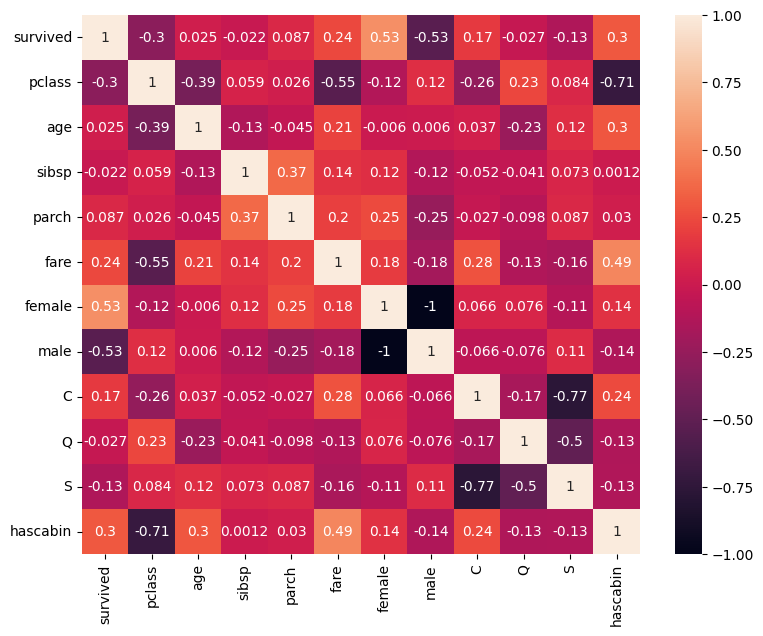

In [24]:
corr_matrix = ds.corr()
plt.figure(figsize=(9,7))
sns.heatmap(corr_matrix, annot=True)
plt.show()

As was mentioned in school, the fare attribute is tied to the ticket itself, not to a single passenger.
This means that some people have artificially higher fare prices than they should have.
A simple solution is to <b>divide the fare price by the number of passengers with the same ticket</b>
and create an attribute <b>fareprice</b> which should be slightly more accurate.

In [25]:
#attempt to divide fares into a few distinct categories
#ended up being more vague and worse
# display(ds.fare.describe())
# ds["fareprice"] = pd.qcut(ds["fare"], q=[0, 0.25, 0.5, 0.75, 1],
#                          labels=[1, 2, 3, 4])
# fp = pd.api.types.CategoricalDtype(categories=[-1 ,1, 2, 3, 4], ordered = True)
# ds["fareprice"] = ds["fareprice"].astype(fp)
# ds.fareprice = ds.fareprice.fillna(-1)
# ds.fareprice = ds.fareprice.cat.codes

#very slightly better than no modification
ds["fareprice"] = (ds["fare"]/ds.groupby("ticket")["fare"].transform("count")).astype('int')
display(ds.fareprice.describe())
display(ds.fare.describe())

ds.drop(["ticket"],axis = 'columns', inplace = True)

ds.info()

count    998.000000
mean      16.676353
std       18.395915
min        0.000000
25%        7.000000
50%        9.000000
75%       20.750000
max      164.000000
Name: fareprice, dtype: float64

count    998.000000
mean      33.371839
std       53.121464
min        0.000000
25%        7.895800
50%       14.500000
75%       31.275000
max      512.329200
Name: fare, dtype: float64

<class 'pandas.core.frame.DataFrame'>
Int64Index: 998 entries, 0 to 999
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   survived   998 non-null    int64  
 1   pclass     998 non-null    int64  
 2   age        998 non-null    float64
 3   sibsp      998 non-null    int64  
 4   parch      998 non-null    int64  
 5   fare       998 non-null    float64
 6   female     998 non-null    uint8  
 7   male       998 non-null    uint8  
 8   C          998 non-null    uint8  
 9   Q          998 non-null    uint8  
 10  S          998 non-null    uint8  
 11  hascabin   998 non-null    bool   
 12  fareprice  998 non-null    int64  
dtypes: bool(1), float64(2), int64(5), uint8(5)
memory usage: 68.2 KB


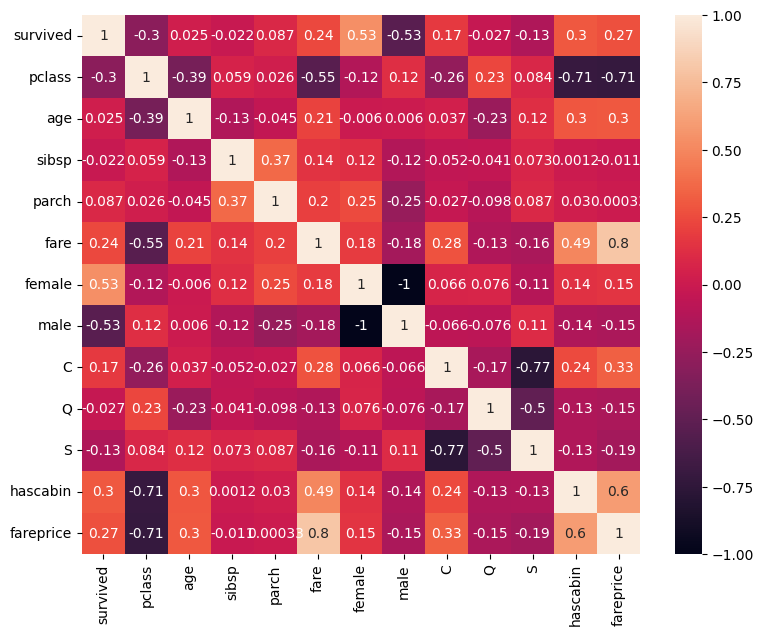

In [26]:
#keeping original fare attribute is very very slightly better than dropping it entirely, maybe lucky seed 
#ds = ds.drop(['fare'], axis = 1)
ds.fare = ds.fare.fillna(-1)

corr_matrix = ds.corr()
plt.figure(figsize=(9,7))
sns.heatmap(corr_matrix, annot=True)
plt.show()

<b>Training phase </b>
Split data into validation and testing

In [27]:
X = ds.drop("survived", axis = 1)
y = ds.survived

ds.info()

display(X.head())
display(y.head())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 998 entries, 0 to 999
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   survived   998 non-null    int64  
 1   pclass     998 non-null    int64  
 2   age        998 non-null    float64
 3   sibsp      998 non-null    int64  
 4   parch      998 non-null    int64  
 5   fare       998 non-null    float64
 6   female     998 non-null    uint8  
 7   male       998 non-null    uint8  
 8   C          998 non-null    uint8  
 9   Q          998 non-null    uint8  
 10  S          998 non-null    uint8  
 11  hascabin   998 non-null    bool   
 12  fareprice  998 non-null    int64  
dtypes: bool(1), float64(2), int64(5), uint8(5)
memory usage: 68.2 KB


,pclass,age,sibsp,parch,fare,female,male,C,Q,S,hascabin,fareprice
0,3,27.0,0,0,7.7958,0,1,0,0,1,False,7
1,3,45.0,0,0,8.0500,0,1,0,0,1,False,8
2,2,-1.0,0,0,0.0000,0,1,0,0,1,False,0
3,3,27.0,0,2,11.1333,1,0,0,0,1,False,11
4,1,28.0,1,0,82.1708,0,1,1,0,0,False,41


0    1
1    1
2    0
3    1
4    0
Name: survived, dtype: int64

In [28]:
random_seed = 27

Xtrain, Xval, ytrain, yval = train_test_split(X, y, test_size=0.4, random_state=random_seed)
Xval, Xtest, yval, ytest = train_test_split(Xval, yval, test_size=0.5, random_state=random_seed)

print(f"Train shape, X: {Xtrain.shape}, y: {ytrain.shape}")
print(f"Val shape, X: {Xval.shape}, y: {yval.shape}")
print(f"Test shape, X: {Xtest.shape}, y: {ytest.shape}")

Train shape, X: (598, 12), y: (598,)
Val shape, X: (200, 12), y: (200,)
Test shape, X: (200, 12), y: (200,)


<s>ab</s>using python packages

<b> Training phase </b>

<b> Decision trees </b>

In [29]:
from sklearn.tree import DecisionTreeClassifier

In [30]:
from sklearn.model_selection import ParameterGrid
param_grid = {
    'max_depth': range(1,40), 
    'criterion': ['entropy', 'gini', 'log_loss']
}
param_comb = ParameterGrid(param_grid)

val_acc = []
train_acc = []
for params in param_comb:
    clf = DecisionTreeClassifier(max_depth=params['max_depth'], criterion=params['criterion'])
    clf.fit(Xtrain, ytrain)
    train_acc.append(metrics.accuracy_score(ytrain, clf.predict(Xtrain)))
    val_acc.append(metrics.accuracy_score(yval, clf.predict(Xval)))

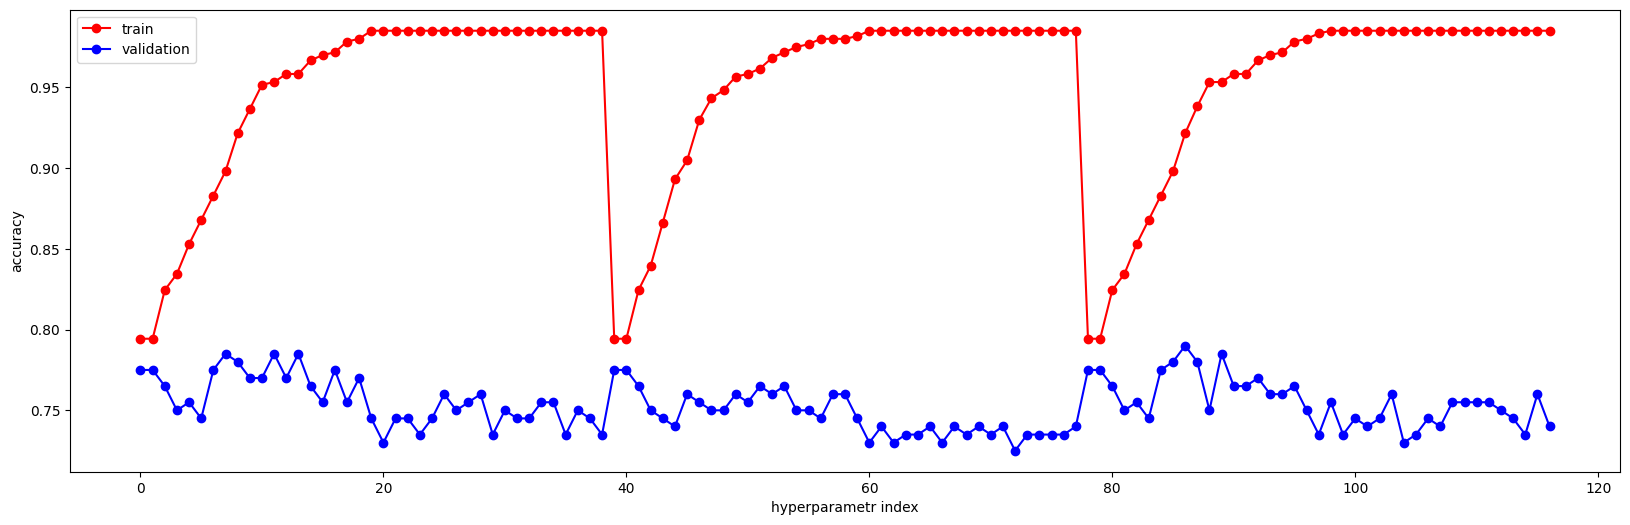

In [31]:
import matplotlib
%matplotlib inline
plt.figure(figsize=(20,6))
plt.plot(train_acc,'or-')
plt.plot(val_acc,'ob-')
plt.xlabel('hyperparametr index')
plt.ylabel('accuracy')
plt.legend(['train', 'validation'])

In [32]:
best_params = param_comb[np.argmax(val_acc)]
best_params

{'max_depth': 9, 'criterion': 'log_loss'}

In [33]:
clf = DecisionTreeClassifier(**best_params) 
clf.fit(Xtrain, ytrain)
print('Validation accuracy: {0:.6f}'.format(metrics.accuracy_score(yval, clf.predict(Xval))))

Validation accuracy: 0.785000


<b> Knn </b>

In [34]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

Best parameters 10
Validation accuracy: 0.8000


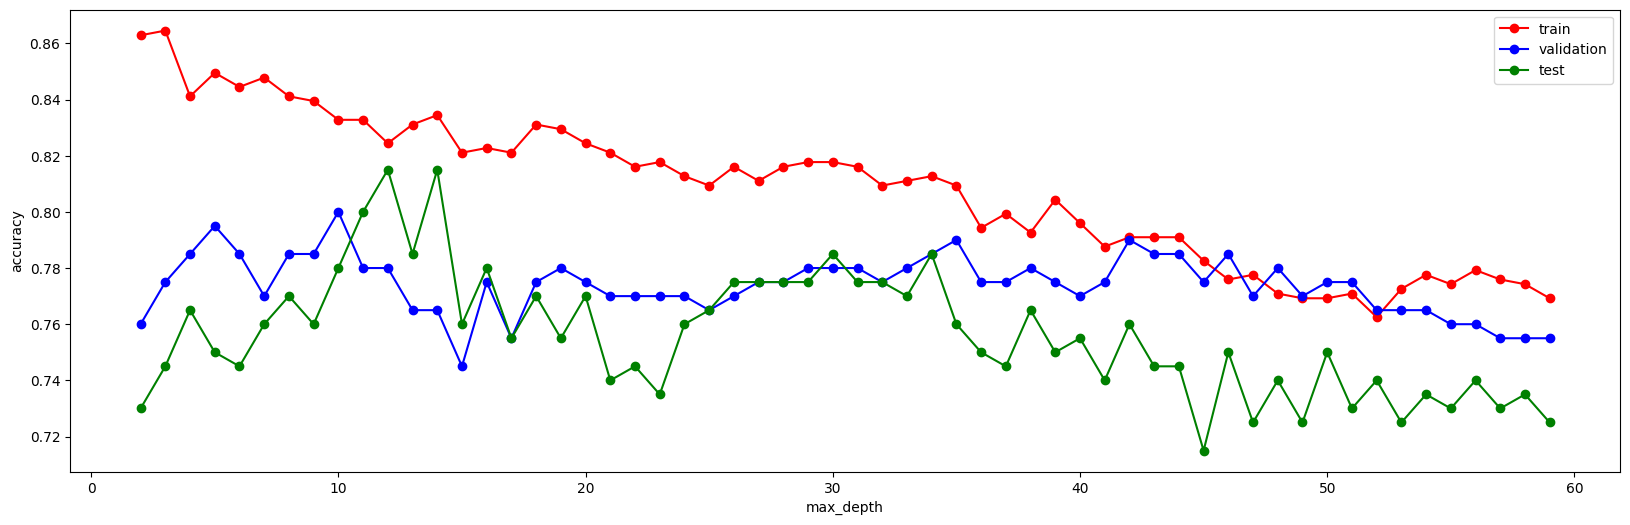

In [35]:
# Min-max scaler
scaler = MinMaxScaler()

#Transform train and val data
Xtrain_scaled = scaler.fit_transform(Xtrain.values)
Xval_scaled = scaler.transform(Xval.values)
Xtest_scaled = scaler.transform(Xtest.values)

val_acc = []
train_acc = []
test_acc = []

kneighbors = range(2,60)
for k in kneighbors:
    clf = KNeighborsClassifier(n_neighbors = k)
    clf.fit(Xtrain_scaled, ytrain)
    val_acc.append(clf.score(Xval_scaled, yval))
    train_acc.append(clf.score(Xtrain_scaled, ytrain))
    test_acc.append(clf.score(Xtest_scaled, ytest))


import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
plt.figure(figsize=(20,6))
plt.plot(kneighbors, train_acc,'or-') 
plt.plot(kneighbors, val_acc,'ob-')
plt.plot(kneighbors, test_acc,'og-')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.legend(['train', 'validation', 'test'])

best_params = np.argmax(val_acc) + 2
print("Best parameters " + str(best_params) )

clf = KNeighborsClassifier(best_params)
clf.fit(Xtrain_scaled, ytrain)
print(f"Validation accuracy: {clf.score(Xval_scaled, yval):0.4f}")

Best parameters 6
Validation accuracy: 0.7950


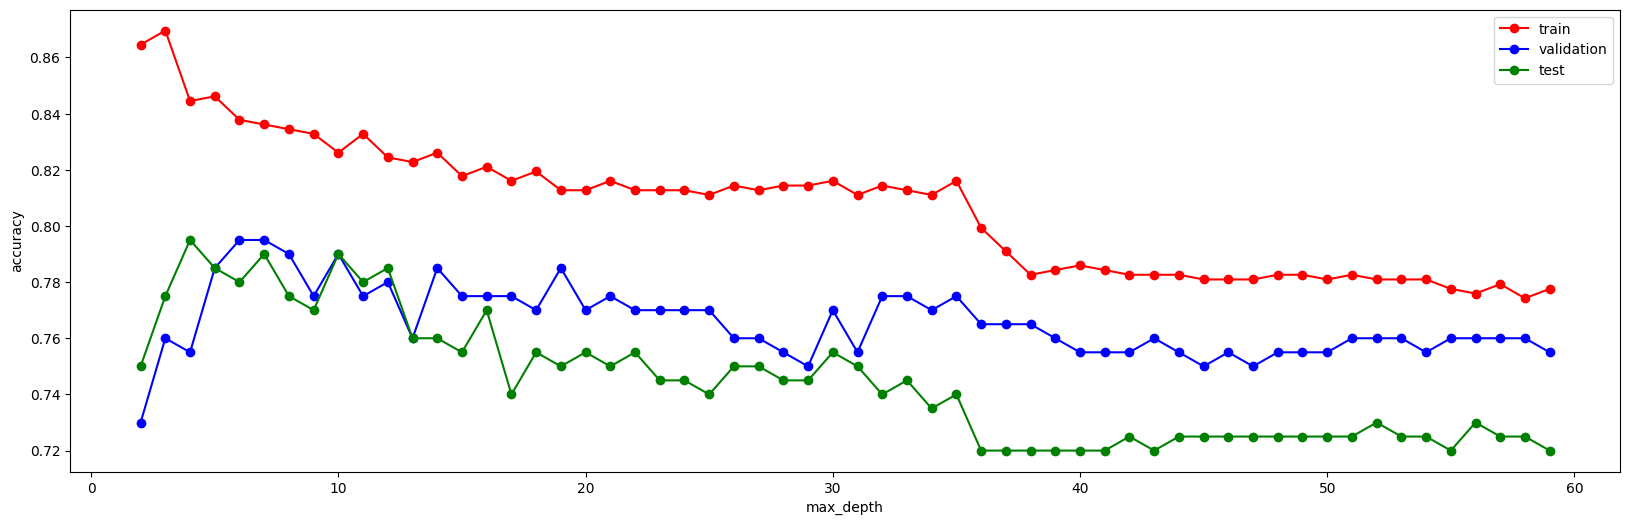

In [36]:
#Standard scaler
scaler = StandardScaler()

#Transform train and val data
Xtrain_scaled = scaler.fit_transform(Xtrain)
Xval_scaled = scaler.transform(Xval)
Xtest_scaled = scaler.transform(Xtest)

val_acc = []
train_acc = []
test_acc = []

kneighbors = range(2,60)
for k in kneighbors:
    clf = KNeighborsClassifier(n_neighbors = k)
    clf.fit(Xtrain_scaled, ytrain)
    val_acc.append(clf.score(Xval_scaled, yval))
    train_acc.append(clf.score(Xtrain_scaled, ytrain))
    test_acc.append(clf.score(Xtest_scaled, ytest))



import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
plt.figure(figsize=(20,6))
plt.plot(kneighbors, train_acc,'or-') 
plt.plot(kneighbors, val_acc,'ob-')
plt.plot(kneighbors, test_acc,'og-')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.legend(['train', 'validation', 'test'])

best_params = np.argmax(val_acc) + 2
print("Best parameters " + str(best_params) )

clf = KNeighborsClassifier(best_params)
clf.fit(Xtrain_scaled, ytrain)
print(f"Validation accuracy: {clf.score(Xval_scaled, yval):0.4f}")

<i> Logistic regression just for fun </i>


In [37]:
# from sklearn.linear_model import LogisticRegression
# clflog = LogisticRegression()
# clflog.fit(Xtrain_scaled,ytrain)

# Yth = clflog.predict(Xval_scaled)

# print(f"Validation accuracy: {clflog.score(Xval_scaled, yval):0.4f}")

<b>Results.csv </b>
Quickly edit the data into the correct form. 

In [38]:
#Load dataset
dataset = pd.read_csv("evaluation.csv")
dataset.info()
# dataset['age'] = dataset.age.isnull() 

#Change the ages to mean of pclass this time, since we can't just drop rowsdataset.loc[(dataset.pclass == 1) & (dataset.age.isnull() == True), 'age'] = dataset.loc[dataset['pclass'] == 1].age.mean().round(1)
# 
# dataset.loc[(dataset.pclass == 2) & (dataset.age.isnull() == True), 'age'] = dataset.loc[dataset['pclass'] == 2].age.mean().round(1)
# dataset.loc[(dataset.pclass == 3) & (dataset.age.isnull() == True), 'age'] = dataset.loc[dataset['pclass'] == 3].age.mean().round(1)


dataset.loc[(dataset.pclass == 1) & (dataset.age.isnull() == True), 'age'] = -1
dataset.loc[(dataset.pclass == 2) & (dataset.age.isnull() == True), 'age'] = -1
dataset.loc[(dataset.pclass == 3) & (dataset.age.isnull() == True), 'age'] = -1


#drop unusued collumns
ds = dataset.drop(["name", "home.dest","ID"], axis = 1)


#one hot encoding for sex and embarked
dummy_sex = pd.get_dummies(ds.sex)
dummy_embarked = pd.get_dummies(ds.embarked)
ds = pd.concat([ds, dummy_sex, dummy_embarked],axis='columns')
ds.drop(["sex", "embarked"], axis = 'columns',inplace=True)


#add hascabin parameter
ds['hascabin'] = ds['cabin'].map(lambda name:(not pd.isnull(name) ))
ds = ds.drop(["cabin"], axis = 1)

#add fareprice parameter
ds["fareprice"] = (ds["fare"]/ds.groupby("ticket")["fare"].transform("count")).astype('int')
ds.drop(["ticket"],axis = 'columns', inplace = True)
ds.fare = ds.fare.fillna(-1)

#new printout added
ds.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         309 non-null    int64  
 1   pclass     309 non-null    int64  
 2   name       309 non-null    object 
 3   sex        309 non-null    object 
 4   age        249 non-null    float64
 5   sibsp      309 non-null    int64  
 6   parch      309 non-null    int64  
 7   ticket     309 non-null    object 
 8   fare       309 non-null    float64
 9   cabin      73 non-null     object 
 10  embarked   308 non-null    object 
 11  home.dest  172 non-null    object 
dtypes: float64(2), int64(4), object(6)
memory usage: 29.1+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     309 non-null    int64  
 1   age        309 non-null    object 
 2   si

Knn with standard scaler and 7 neighbors ended up as the best one so we'll be using it.

In [39]:
XEV = ds
display(XEV.head())

#same as knn above
random_seed = 27
X_scaledEV = scaler.transform(XEV)
best_params = 7
clf = KNeighborsClassifier(best_params)
clf.fit(Xtrain_scaled, ytrain)
print(f"Validation accuracy: {clf.score(Xval_scaled, yval):0.4f}")
print(f"Test accuracy: {clf.score(Xtest_scaled, ytest):0.4f}")


Ypr = clf.predict(X_scaledEV)
results = pd.DataFrame()
results["ID"] = dataset["ID"]
results["survived"] = Ypr
display(results.head( n = 15))


results.to_csv("results.csv", sep='\t')

,pclass,age,sibsp,parch,fare,female,male,C,Q,S,hascabin,fareprice
0,1,False,0,2,164.8667,1,0,0,0,1,True,54
1,1,False,0,0,76.2917,1,0,1,0,0,True,76
2,1,False,1,0,53.1000,1,0,0,0,1,True,53
3,3,False,0,0,7.7750,0,1,0,0,1,False,7
4,3,True,0,0,7.7500,0,1,0,1,0,False,7


Validation accuracy: 0.7950
Test accuracy: 0.7900


,ID,survived
0,1000,1
1,1001,1
2,1002,1
3,1003,0
4,1004,0
5,1005,0
6,1006,0
7,1007,0
8,1008,1
9,1009,0


<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=7ed3a42a-b196-423b-a0db-5445cbea51e7' target="_blank">
 </img>
Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>